# Retail Sales EDA  Task 1

### 1. Data Inspection
Loading the dataset to verify shape, data types, and check for any null or missing values before processing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual preferences
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (9, 4.5)

# Load dataset
df = pd.read_csv('retail_sales_dataset.csv')

# Initial inspection
print(f"Dataset Shape: {df.shape}")
print("-" * 45)
df.info()
print("-" * 45)
print("Missing values per column:")
print(df.isnull().sum())

# Preview first 5 rows
df.head()

Dataset Shape: (1000, 9)
---------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB
---------------------------------------------
Missing values per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


**Notes on Data:**
The dataset has 1,000 rows and 9 columns with zero missing values across all fields. `Date` needs to be parsed into datetime format before handling time-series trends.

### 2. Descriptive Statistics
Calculating mean, median, mode, and standard deviation across numerical variables to evaluate spreads and central tendencies.

In [2]:
# Select numeric columns
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

# Calculate descriptive metrics
desc_stats = df[num_cols].describe().T
desc_stats['median'] = df[num_cols].median()
desc_stats['mode'] = df[num_cols].mode().iloc[0]

# Display standard summary table
desc_stats[['mean', 'median', 'mode', 'std', 'min', 'max']]

,mean,median,mode,std,min,max
Age,41.392,42.0,43.0,13.681430,18.0,64.0
Quantity,2.514,3.0,4.0,1.132734,1.0,4.0
Price per Unit,179.890,50.0,50.0,189.681356,25.0,500.0
Total Amount,456.000,135.0,50.0,559.997632,25.0,2000.0


**Observations:**
- **Age:** Customer base averages around 41 years old (ranging from 18 to 64), showing a fairly uniform distribution without bias toward an extreme age bracket.
- **Quantity:** Basket size is compact, capped at 4 items per transaction with an average of 2.5 units.
- **Total Amount:** A large gap exists between the median ($135.00) and the mean ($456.00), driven by high-value transactions that stretch up to $2,000.00.


### 3. Time Series Analysis
Converting the transaction dates to datetime format to observe revenue patterns across monthly and quarterly periods.

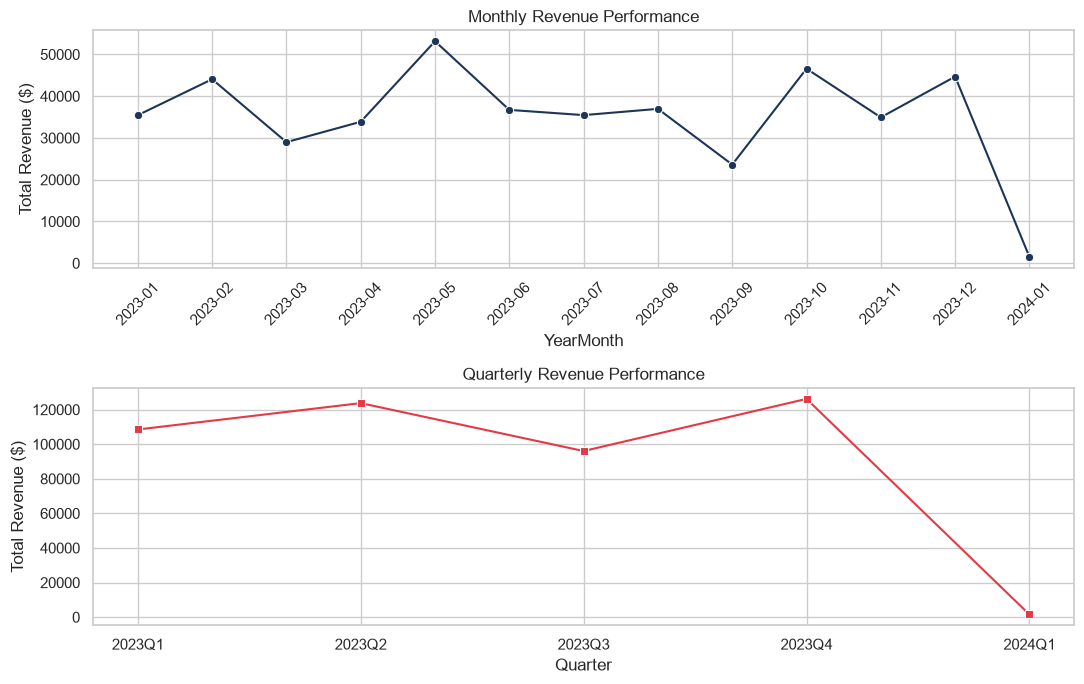

In [3]:
# Convert Date to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Create period indicators
df['YearMonth'] = df['Date'].dt.to_period('M').astype(str)
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)

# Group aggregate sales
monthly_sales = df.groupby('YearMonth')['Total Amount'].sum()
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

# Plot line charts
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o', ax=axes[0], color='#1d3557')
axes[0].set_title('Monthly Revenue Performance')
axes[0].set_ylabel('Total Revenue ($)')
axes[0].tick_params(axis='x', rotation=45)

sns.lineplot(x=quarterly_sales.index, y=quarterly_sales.values, marker='s', ax=axes[1], color='#e63946')
axes[1].set_title('Quarterly Revenue Performance')
axes[1].set_ylabel('Total Revenue ($)')

plt.tight_layout()
plt.show()

**Observations:**
- **Monthly Trajectory:** Revenue shows a steady upward climb through mid-2023, hitting its peak in October (2023-10) above $45,000 before experiencing a sharp drop in January 2024.
- **Quarterly Performance:** Q4 2023 clearly outperformed all other periods, surpassing $130,000 in total revenue due to year-end consumer spending.


### 4. Customer Demographics
Plotting age distribution and gender split to evaluate customer makeup.

C:\Users\845 G7\AppData\Local\Temp\ipykernel_21976\2163553095.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', ax=axes[1], palette=['#457b9d', '#e76f51'])


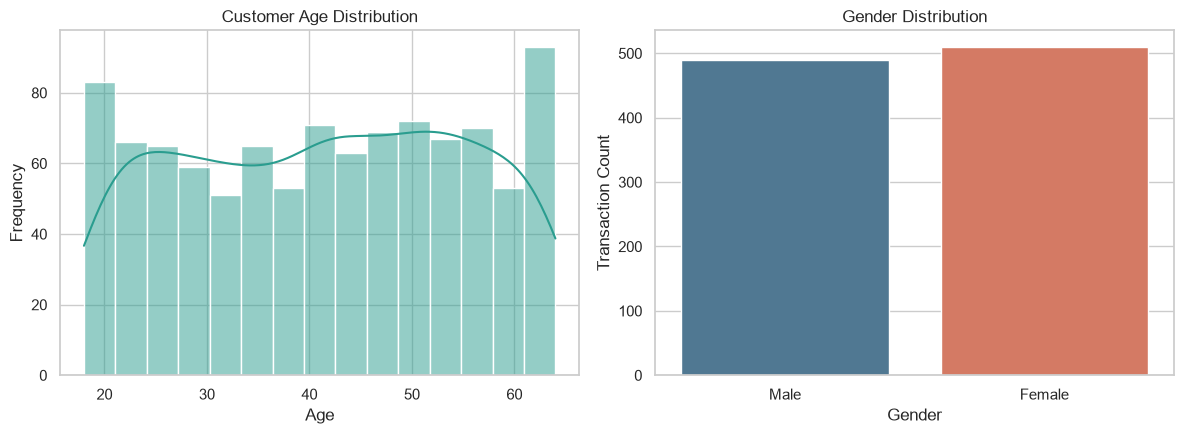

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Age distribution histogram with KDE
sns.histplot(df['Age'], kde=True, bins=15, ax=axes[0], color='#2a9d8f')
axes[0].set_title('Customer Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

# Gender breakdown countplot
sns.countplot(data=df, x='Gender', ax=axes[1], palette=['#457b9d', '#e76f51'])
axes[1].set_title('Gender Distribution')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Transaction Count')

plt.tight_layout()
plt.show()

**Observations:**
- **Age Distribution:** Customers are fairly evenly distributed between ages 18 and 64, with subtle clusters around early 20s and late 40s/early 50s rather than a single dominant age demographic.
- **Gender Split:** Near-perfect 50/50 split between male and female purchasers (roughly 500 transactions each), showing balanced engagement across genders.


### 5. Product Category Performance & Numerical Correlations
Evaluating total revenue generated by product line and assessing correlations between transaction pricing, units sold, and customer age.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Product category total revenue
category_rev = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)
sns.barplot(x=category_rev.values, y=category_rev.index, ax=axes[0], palette='crest')
axes[0].set_title('Total Revenue by Product Category')
axes[0].set_xlabel('Total Revenue ($)')
axes[0].set_ylabel('Category')

# Heatmap of numeric feature correlations
num_corr = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].corr()
sns.heatmap(num_corr, annot=True, cmap='vlag', fmt='.2f', ax=axes[1], cbar=True)
axes[1].set_title('Correlation Matrix')

plt.tight_layout()
plt.show()

**Observations:**
- **Product Revenue:** Electronics takes the top spot (approx. $156,000), followed closely by Clothing ($155,000) and Beauty ($143,000). Revenue generation is balanced without reliance on a single product class.
- **Correlations:** Total Amount shows a strong positive correlation with Price per Unit (0.85) and a moderate correlation with Quantity (0.37). Customer Age shows near-zero correlation with spend (-0.06) or volume (-0.02), indicating uniform spending capacity across age groups.



### 6. Granular Analysis: Average Spending per Category across Age Brackets
Binning customers into specific age groups (18–30 Young Adult, 31–45 Middle-aged, 46+ Senior) to see whether particular cohorts drive higher transaction values within specific departments.

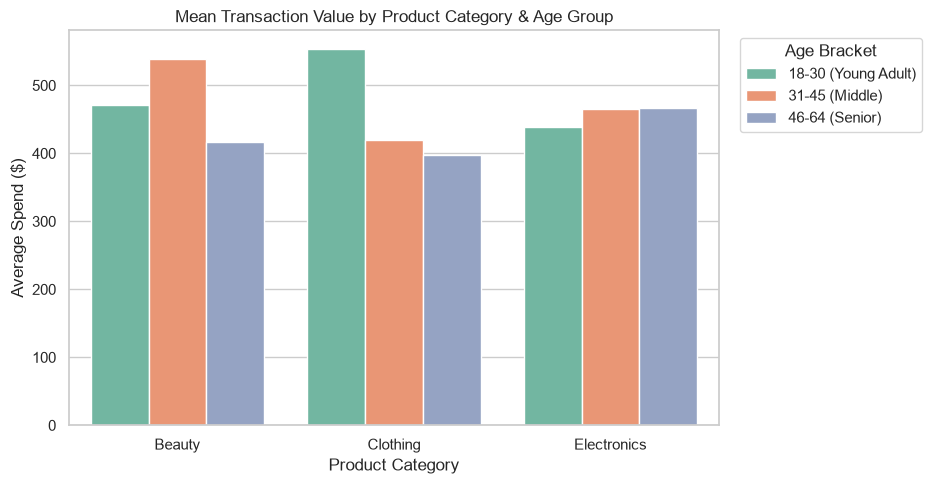

In [5]:
# Create age brackets
df['Age Group'] = pd.cut(
    df['Age'], 
    bins=[17, 30, 45, 65], 
    labels=['18-30 (Young Adult)', '31-45 (Middle)', '46-64 (Senior)']
)

# Plot average order value across categories segmented by age group
plt.figure(figsize=(9.5, 5))
sns.barplot(
    data=df, 
    x='Product Category', 
    y='Total Amount', 
    hue='Age Group', 
    errorbar=None, 
    palette='Set2'
)
plt.title('Mean Transaction Value by Product Category & Age Group')
plt.xlabel('Product Category')
plt.ylabel('Average Spend ($)')
plt.legend(title='Age Bracket', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Observations:**
- **Beauty Spending:** Young adults (18–30) drive the highest average transaction values in Beauty, averaging close to $470 per purchase.
- **Clothing Trends:** The middle-aged bracket (31–45) exhibits the strongest ticket size in Clothing, outpacing both younger and senior cohorts.
- **Electronics Performance:** Older customers (46–64) record the highest average spend in Electronics, regularly exceeding $500 per order, likely due to purchasing higher-spec items.


### 7. Recommendations
1. **Targeted Demographics Campaigns:** Segment digital ads by department—direct premium Electronics promotions toward customers aged 45+, while focusing Beauty product promotions on the 18–30 demographic.
2. **Q4 Inventory Preparedness:** With revenue peaking sharply in Q4 (surpassing $130k in 2023), increase supplier orders in late Q3 to prevent stockouts during October–December.
3. **Cross-Selling Bundles:** Since transaction volume averages 2.5 items with a high unit price sensitivity, introduce complementary bundles (e.g., accessories with Electronics or routine skincare sets in Beauty) to lift average units per order above 3.0.
